# Part 2, Rohan: clustering stations

**Idea (lecture 14).** Group the 468 stations into clusters of stations that behave alike, then use the clusters in two ways:
1. **Per-cluster models:** fit a separate model for each cluster (a middle ground between one pooled model and 468 per-station models).
2. **Cluster features:** keep one pooled model but add, for each station, the current level of *its cluster* (stations that behave alike, wherever they are), next to the distance-based neighbour features it already has.

**Base model:** Sanath's Laplace linear model on `log1p(PM2.5)` with the smeared-mean forecast (`cache/probmodels_C.py`) and his 25 features (`cache/features_C.py`), the best model so far (validation RMSE 28.16). So every comparison below isolates the effect of the clusters.

**No leakage:** station profiles used for clustering are computed from training hours only (up to 31 Aug 12:00). Cluster features at issue time t use readings at or before t.

In [1]:
import os, sys, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 0
random.seed(SEED); np.random.seed(SEED)

ROOT = Path.cwd()
if not (ROOT / "baseline.py").exists():
    ROOT = ROOT.parent                      # notebook lives in models/
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import baseline as B
from cache import features_C as FC
from cache import probmodels_C as PM
B.self_check()

baseline.py OK


,RMSE,MAE,RMSE Sep,MAE Sep,RMSE Oct,MAE Oct,RMSE Nov,MAE Nov
Persistence,32.75,17.47,23.33,8.91,20.22,11.97,47.81,31.70
Ridge (Part 1),29.58,18.16,20.34,10.35,19.36,13.46,43.06,30.81


## 1. Data, features and the pooled reference model

In [2]:
W, stations = B.load_data()
T_train, T_val = B.issue_times()
y_train, y_val = B.targets(W, T_train), B.targets(W, T_val)
N = W.shape[1]

ctx = FC.build_ctx(W, stations)
X_train, names, groups = FC.extract_features(W, T_train, ctx)
X_val, _, _ = FC.extract_features(W, T_val, ctx)

def rmse(p, y=None):
    y = y_val if y is None else y
    return float(np.sqrt(np.mean((np.clip(p, 0, None) - y) ** 2)))

def mae(p):
    return float(np.mean(np.abs(np.clip(p, 0, None) - y_val)))

pooled = PM.LogLaplaceForecaster().fit(X_train, y_train)
pred_pooled = pooled.predict(X_val)
print(f"Pooled Laplace (Sanath's final): val RMSE {rmse(pred_pooled):.2f}, MAE {mae(pred_pooled):.2f}")

Pooled Laplace (Sanath's final): val RMSE 28.16, MAE 15.74


## 2. Station profiles (training hours only)
Each station is described by numbers that summarise how it behaves, computed on log PM2.5 over Jan – Aug:
- **monthly:** its mean level in each month Jan – Aug (8 numbers): the seasonal shape and overall level;
- **diurnal:** its mean by hour of day minus its overall mean (24 numbers): the shape of its daily cycle;
- **location:** x, y in km.

Profiles are standardised before clustering so that every column counts equally.

In [3]:
W_tr = np.log1p(W.loc[:"2024-08-31 12:00"])
monthly = W_tr.groupby(W_tr.index.month).mean().T.to_numpy()             # 468 x 8
diurnal = W_tr.groupby(W_tr.index.hour).mean().T
diurnal = diurnal.sub(diurnal.mean(axis=1), axis=0).to_numpy()            # 468 x 24, shape only
location = stations[["x_km", "y_km"]].to_numpy()                           # 468 x 2

PROFILES = {
    "monthly": monthly,
    "diurnal": diurnal,
    "monthly+diurnal": np.hstack([monthly, diurnal]),
    "location": location,
    "monthly+location": np.hstack([monthly, location]),
}
PROFILES_Z = {k: StandardScaler().fit_transform(v) for k, v in PROFILES.items()}
{k: v.shape for k, v in PROFILES.items()}

{'monthly': (468, 8),
 'diurnal': (468, 24),
 'monthly+diurnal': (468, 32),
 'location': (468, 2),
 'monthly+location': (468, 10)}

## 3. How many clusters? (unsupervised view)
For each profile set: k-means for K = 2 … 10, with the within-cluster sum of squares (elbow plot) and the silhouette score (how much closer a station is to its own cluster than to the next one; higher is better).

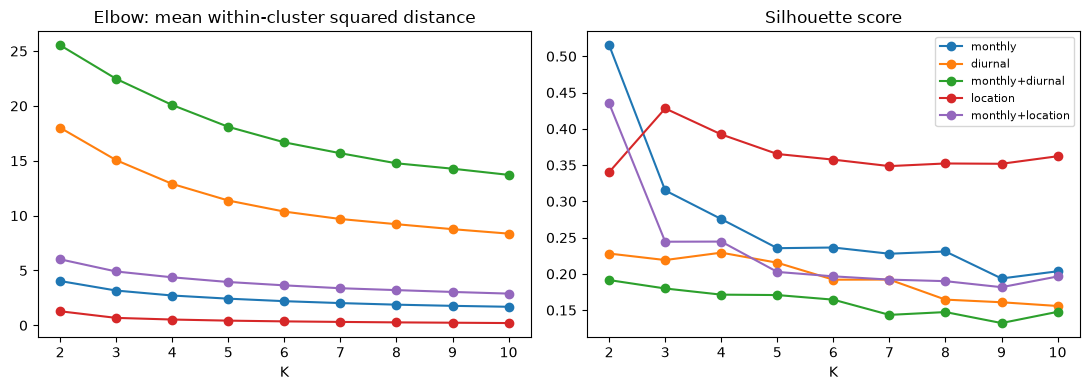

,2,3,4,5,6,7,8,9,10
monthly,0.515,0.315,0.276,0.235,0.236,0.228,0.231,0.194,0.204
diurnal,0.228,0.219,0.229,0.215,0.192,0.192,0.165,0.161,0.156
monthly+diurnal,0.191,0.180,0.171,0.171,0.164,0.143,0.147,0.132,0.148
location,0.340,0.428,0.392,0.365,0.357,0.349,0.352,0.352,0.362
monthly+location,0.435,0.244,0.245,0.203,0.197,0.192,0.190,0.182,0.196


In [4]:
Ks = range(2, 11)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sil_table = {}
for name, Z in PROFILES_Z.items():
    inertia, sil = [], []
    for K in Ks:
        km = KMeans(K, n_init=10, random_state=SEED).fit(Z)
        inertia.append(km.inertia_ / len(Z)); sil.append(silhouette_score(Z, km.labels_))
    axes[0].plot(list(Ks), inertia, marker="o", label=name)
    axes[1].plot(list(Ks), sil, marker="o", label=name)
    sil_table[name] = dict(zip(Ks, np.round(sil, 3)))
axes[0].set_title("Elbow: mean within-cluster squared distance"); axes[0].set_xlabel("K")
axes[1].set_title("Silhouette score"); axes[1].set_xlabel("K")
axes[1].legend(fontsize=8); fig.tight_layout(); plt.show()
pd.DataFrame(sil_table).T

## 4. What the clusters look like
Example: k-means with K = 4 on the monthly + diurnal profile. Left: stations on the map, coloured by cluster. Right: each cluster's mean monthly level.

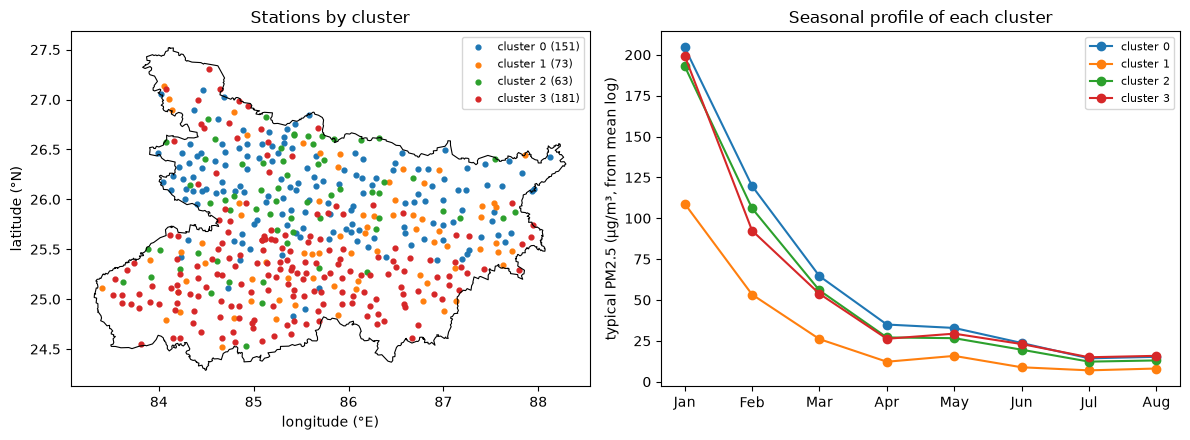

In [5]:
boundary = pd.read_csv("data/bihar_boundary.csv")
K_SHOW = 4
lab_show = KMeans(K_SHOW, n_init=10, random_state=SEED).fit_predict(PROFILES_Z["monthly+diurnal"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
ax.plot(boundary.iloc[:, 0], boundary.iloc[:, 1], color="black", lw=0.8)
for k in range(K_SHOW):
    m = lab_show == k
    ax.scatter(stations.longitude[m], stations.latitude[m], s=12, label=f"cluster {k} ({m.sum()})")
ax.set_xlabel("longitude (°E)"); ax.set_ylabel("latitude (°N)"); ax.set_title("Stations by cluster"); ax.legend(fontsize=8)

ax = axes[1]
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug"]
for k in range(K_SHOW):
    ax.plot(months, np.expm1(monthly[lab_show == k].mean(axis=0)), marker="o", label=f"cluster {k}")
ax.set_ylabel("typical PM2.5 (µg/m³, from mean log)"); ax.set_title("Seasonal profile of each cluster"); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

## 5. Use 1: a separate model for each cluster
Rows are split by their station's cluster; each cluster gets its own Laplace model (same features, same settings).

In [6]:
def per_cluster_predict(labels):
    lab_tr, lab_va = np.tile(labels, len(T_train)), np.tile(labels, len(T_val))
    pred = np.zeros_like(y_val)
    for k in np.unique(labels):
        model = PM.LogLaplaceForecaster().fit(X_train[lab_tr == k], y_train[lab_tr == k])
        pred[lab_va == k] = model.predict(X_val[lab_va == k])
    return pred

rows = []
for name, Z in PROFILES_Z.items():
    for K in [2, 3, 5, 8]:
        labels = KMeans(K, n_init=10, random_state=SEED).fit_predict(Z)
        p = per_cluster_predict(labels)
        rows.append({"profile": name, "K": K, "smallest cluster": int(np.bincount(labels).min()),
                     "val RMSE": rmse(p), "val MAE": mae(p)})
per_cluster = pd.DataFrame(rows).sort_values("val RMSE")
print(f"pooled reference: {rmse(pred_pooled):.2f} / {mae(pred_pooled):.2f}")
per_cluster.round(2)

pooled reference: 28.16 / 15.74


,profile,K,smallest cluster,val RMSE,val MAE
4,diurnal,2,229,28.17,15.76
8,monthly+diurnal,2,208,28.21,15.78
16,monthly+location,2,105,28.21,15.73
0,monthly,2,107,28.21,15.73
9,monthly+diurnal,3,77,28.24,15.75
5,diurnal,3,125,28.26,15.83
12,location,2,222,28.32,15.80
1,monthly,3,65,28.35,15.80
10,monthly+diurnal,5,4,28.35,15.82
14,location,5,82,28.36,15.86


## 6. Use 2: pooled model + cluster features
For each station and issue time t, three new features: the mean log PM2.5 of its cluster at t, the cluster's mean over the last 24 h, and the station's anomaly versus its cluster at t. A cluster is a group of stations that *behave* alike, which can be far apart; the existing `nbr` features use the nearest stations by distance.

Hard version: k-means labels. Soft version: a Gaussian mixture model (GMM), where each station belongs to every cluster with a probability, and the cluster mean is probability-weighted.

In [7]:
def cluster_features(T, weights):
    """weights: (468 x K) membership matrix (one-hot for k-means, probabilities for GMM).
    Returns (len(T)*468 x 3): cluster mean at t, cluster mean over 24 h, anomaly vs cluster at t."""
    L = np.log1p(B.lag_stack(W, T, 24))                 # (n_times, 468, 24), readings at or before t
    now, m24 = L[:, :, 0], L.mean(axis=2)
    Wn = weights / weights.sum(axis=0, keepdims=True)   # each cluster's average over its members
    c_now = (now @ Wn) @ weights.T / weights.sum(axis=1)  # back to stations
    c_24 = (m24 @ Wn) @ weights.T / weights.sum(axis=1)
    return np.column_stack([c_now.ravel(), c_24.ravel(), (now - c_now).ravel()])

def with_cluster_features(weights):
    Ftr, Fva = cluster_features(T_train, weights), cluster_features(T_val, weights)
    model = PM.LogLaplaceForecaster().fit(np.hstack([X_train, Ftr]), y_train)
    return model.predict(np.hstack([X_val, Fva]))

rows = []
for name, Z in PROFILES_Z.items():
    for K in [3, 5, 8]:
        km = np.eye(K)[KMeans(K, n_init=10, random_state=SEED).fit_predict(Z)]
        p = with_cluster_features(km)
        rows.append({"profile": name, "K": K, "clustering": "k-means", "val RMSE": rmse(p), "val MAE": mae(p)})
        gmm = GaussianMixture(K, covariance_type="diag", random_state=SEED, n_init=3).fit(Z)
        p = with_cluster_features(gmm.predict_proba(Z))
        rows.append({"profile": name, "K": K, "clustering": "GMM (soft)", "val RMSE": rmse(p), "val MAE": mae(p)})
cluster_feat = pd.DataFrame(rows).sort_values("val RMSE")
print(f"pooled reference: {rmse(pred_pooled):.2f} / {mae(pred_pooled):.2f}")
cluster_feat.round(2)

pooled reference: 28.16 / 15.74


,profile,K,clustering,val RMSE,val MAE
13,monthly+diurnal,3,GMM (soft),28.10,15.67
26,monthly+location,5,k-means,28.10,15.68
19,location,3,GMM (soft),28.11,15.69
12,monthly+diurnal,3,k-means,28.11,15.69
16,monthly+diurnal,8,k-means,28.11,15.68
28,monthly+location,8,k-means,28.11,15.69
21,location,5,GMM (soft),28.12,15.68
22,location,8,k-means,28.12,15.70
14,monthly+diurnal,5,k-means,28.13,15.68
18,location,3,k-means,28.13,15.72


## 7. Is the best cluster variant really better?
Block bootstrap over validation days (days are correlated, so whole 7-day blocks are resampled), for the best variant of each use against the pooled model. A negative difference means the cluster version is better.

In [8]:
def day_sq(pred):
    return ((np.clip(pred, 0, None) - y_val) ** 2).reshape(len(T_val), -1).mean(axis=1)

def bootstrap_gap(pred_a, pred_b, n=2000, block=7):
    rng = np.random.default_rng(SEED)
    da, db = day_sq(pred_a), day_sq(pred_b)
    nd, out = len(da), []
    for _ in range(n):
        starts = rng.integers(0, nd - block + 1, size=nd // block + 1)
        idx = np.concatenate([np.arange(s, s + block) for s in starts])[:nd]
        out.append(np.sqrt(da[idx].mean()) - np.sqrt(db[idx].mean()))
    return np.percentile(out, [2.5, 50, 97.5]).round(2)

best_pc = per_cluster.iloc[0]
labels_pc = KMeans(int(best_pc.K), n_init=10, random_state=SEED).fit_predict(PROFILES_Z[best_pc.profile])
pred_pc = per_cluster_predict(labels_pc)

best_cf = cluster_feat.iloc[0]
Z = PROFILES_Z[best_cf.profile]; K = int(best_cf.K)
if best_cf.clustering == "k-means":
    weights = np.eye(K)[KMeans(K, n_init=10, random_state=SEED).fit_predict(Z)]
else:
    weights = GaussianMixture(K, covariance_type="diag", random_state=SEED, n_init=3).fit(Z).predict_proba(Z)
pred_cf = with_cluster_features(weights)

print(f"best per-cluster  ({best_pc.profile}, K={int(best_pc.K)}): {rmse(pred_pc):.2f}  minus pooled: {bootstrap_gap(pred_pc, pred_pooled)}")
print(f"best cluster-feat ({best_cf.profile}, K={K}, {best_cf.clustering}): {rmse(pred_cf):.2f}  minus pooled: {bootstrap_gap(pred_cf, pred_pooled)}")

best per-cluster  (diurnal, K=2): 28.17  minus pooled: [-0.09  0.01  0.1 ]
best cluster-feat (monthly+diurnal, K=3, GMM (soft)): 28.10  minus pooled: [-0.11 -0.04  0.03]


## 8. Comparison with the baselines and save predictions

In [9]:
p_val = B.persistence(W, T_val)
def row(name, p):
    e = B.evaluate(p, y_val, T_val)
    return {"model": name, "val RMSE": e["RMSE"], "val MAE": e["MAE"], "Sep": e["RMSE Sep"], "Oct": e["RMSE Oct"], "Nov": e["RMSE Nov"]}
table = pd.DataFrame([
    row("Persistence", p_val),
    row("Ridge (Part 1)", B.part1_ridge_predict(W, stations, T_val)),
    row("C: pooled Laplace (Sanath, final)", pred_pooled),
    row(f"E: per-cluster Laplace ({best_pc.profile}, K={int(best_pc.K)})", pred_pc),
    row(f"E: pooled + cluster features ({best_cf.profile}, K={K}, {best_cf.clustering})", pred_cf),
]).set_index("model")
display(table.round(2))

Path("preds").mkdir(exist_ok=True)
idx = pd.DatetimeIndex(T_val) + pd.Timedelta(hours=24)
for fname, p in [("rohan_cluster_models", pred_pc), ("rohan_cluster_features", pred_cf)]:
    pd.DataFrame(np.clip(p, 0, None).reshape(len(T_val), -1), index=idx, columns=W.columns).to_parquet(f"preds/{fname}.parquet")
print("saved preds/rohan_cluster_models.parquet and preds/rohan_cluster_features.parquet")

,val RMSE,val MAE,Sep,Oct,Nov
model,,,,,
Persistence,32.75,17.47,23.33,20.22,47.81
Ridge (Part 1),29.58,18.16,20.34,19.36,43.06
"C: pooled Laplace (Sanath, final)",28.16,15.74,20.05,17.57,41.05
"E: per-cluster Laplace (diurnal, K=2)",28.17,15.76,19.91,17.56,41.14
"E: pooled + cluster features (monthly+diurnal, K=3, GMM (soft))",28.10,15.67,20.07,17.51,40.94


saved preds/rohan_cluster_models.parquet and preds/rohan_cluster_features.parquet


## 9. Interpretation

**Are there natural groups of stations? Only weakly (section 3).** Silhouette scores for the behaviour profiles are low: 0.13 to 0.23 for the diurnal and monthly + diurnal profiles at K = 3 to 10 (1 means well separated, 0 means stations sit between clusters). The one high value, monthly at K = 2 (0.52), just splits off a group of cleaner stations. Location clusters score higher (0.43 at K = 3), but only because k-means cuts a map into tidy regions. So stations form a continuum of behaviour rather than distinct types.

**What the clusters look like (section 4).** With K = 4 on monthly + diurnal profiles, three clusters share almost the same seasonal curve (about 200 µg/m³ in January falling to 15 in July) and differ mainly in their daily cycle. One cluster (73 stations) sits at roughly half that level all year: cleaner sites spread across the whole state, not one region. Behaviour-based clusters therefore group stations that are far apart, which distance-based neighbours cannot do.

**Use 1, a separate model per cluster, does not help (section 5).** The best variant (diurnal profiles, K = 2) gives 28.17 against 28.16 for the pooled model, and every larger K is worse, up to 28.62 at K = 8. Splitting the rows gives each model less data, and the pooled model already adapts to each station through its own features (its lags, 7-day mean and neighbours), so a per-cluster intercept and slopes add little. Very small clusters (2 to 4 stations at K = 5 or 8) make it worse.

**Use 2, cluster features, gives a gain too small to trust (sections 6 and 7).** The best variant (soft GMM clusters on monthly + diurnal profiles, K = 3) reaches 28.10 / 15.67 against 28.16 / 15.74. Almost every variant lands between 28.10 and 28.18, and the block-bootstrap interval for best variant minus pooled is [-0.11, +0.03]: it includes zero. The information in a cluster's current level is largely already in the model's neighbour and network features, since stations that behave alike are mostly polluted by the same regional air. Soft (GMM) and hard (k-means) clusters perform the same.

**Conclusion.** Clustering is a sound idea for adding station-type information, but here it does not improve on the pooled Laplace model by more than noise, so we keep Sanath's model as the final one. For the report this supports the same picture as the other Part 2 work: the errors that remain are a handful of November smog days that no grouping of PM2.5 histories can anticipate.